# 02 · Análisis temporal

Tendencia anual (con el año en curso marcado como parcial), patrón hora × día, descomposición STL del hurto y una **serie temporal interrumpida** para medir el cambio con el COVID-19 contra un contrafactual ajustado solo con datos anteriores a marzo de 2020.

In [1]:
import json
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from delitos_chicago.config import FIGURAS, PROCESADOS, REPORTES
import delitos_chicago.pipeline  # los módulos fijan el backend Agg al importarse; después se activa el inline
%matplotlib inline
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

In [2]:
from delitos_chicago.pipeline import cargar_datos
from delitos_chicago.pronostico import ultimo_mes_completo
df, renombres, conteos = cargar_datos(PROCESADOS / "delitos_parquet")
mes_completo = ultimo_mes_completo(df["fecha"].max())
anio_completo = mes_completo.year if mes_completo.month == 12 else mes_completo.year - 1
completos = df[df["anio"] <= anio_completo]
print(f"{len(df):,} registros · último dato {df['fecha'].max():%Y-%m-%d} · último mes completo {mes_completo:%Y-%m} · años completos 2001–{anio_completo}")

8,665,676 registros · último dato 2026-10-16 · último mes completo 2026-09 · años completos 2001–2025


## 1. Tendencia anual

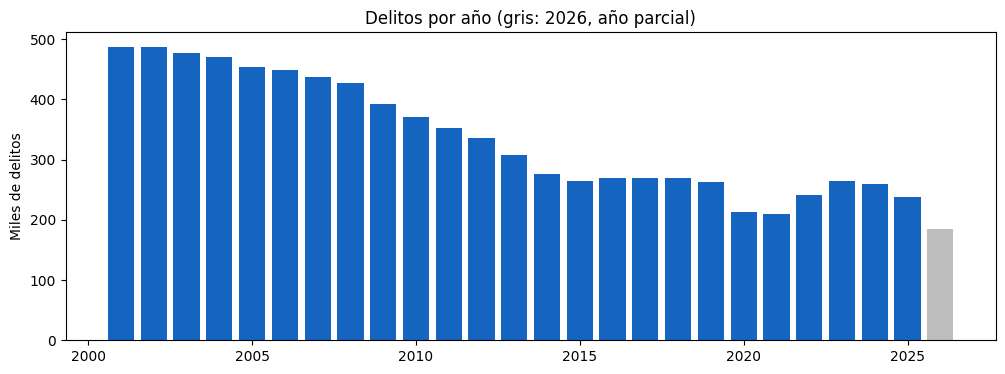

Máximo: 2002 (486,843) · 2025: 238,176 (-51.1 %)


In [3]:
anual = df.groupby("anio").size()
colores = ["#BDBDBD" if a > anio_completo else "#1565C0" for a in anual.index]
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(anual.index, anual.values / 1000, color=colores)
ax.set_ylabel("Miles de delitos")
ax.set_title(f"Delitos por año (gris: {anio_completo + 1}, año parcial)")
plt.show()
print(f"Máximo: {anual.idxmax()} ({anual.max():,}) · {anio_completo}: {anual[anio_completo]:,} "
      f"({(anual[anio_completo] / anual.max() - 1) * 100:+.1f} %)")

## 2. Hora × día de la semana

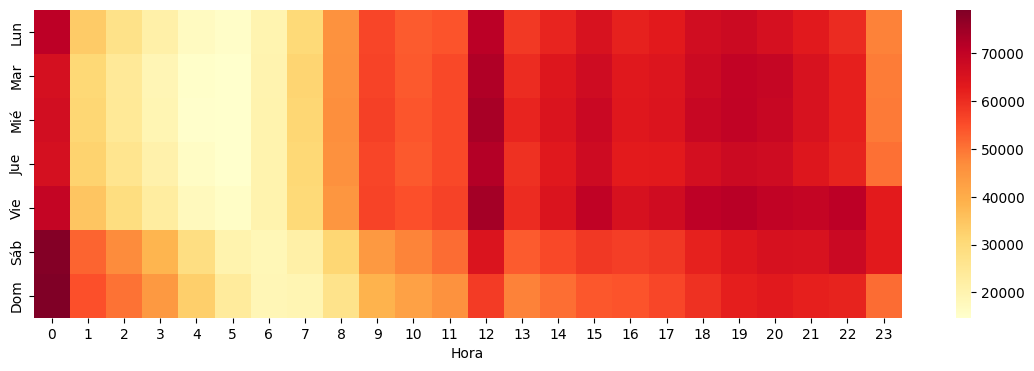

{'franja_pico_inicio': 18,
 'franja_pico_fin': 22,
 'franja_pico_pct': 22.0,
 'hora_pico_sin_medianoche': 12,
 'hora_minima': 5,
 'pct_medianoche': 5.9,
 'dia_maximo': 'Vie',
 'dia_minimo': 'Dom',
 'dif_dia_max_min_pct': 9.8}

In [4]:
import seaborn as sns
from delitos_chicago.temporal import mapa_calor_hora_dia, patron_horario
tabla = mapa_calor_hora_dia(completos)
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(tabla, cmap="YlOrRd", ax=ax)
ax.set_xlabel("Hora")
plt.show()
{k: v for k, v in patron_horario(completos).items() if k != "por_hora"}

La franja de cuatro horas con más delitos se busca sin la medianoche, porque las 00:00 concentran registros sin hora exacta. Es la misma cifra que cita el README.

## 3. Descomposición STL del hurto

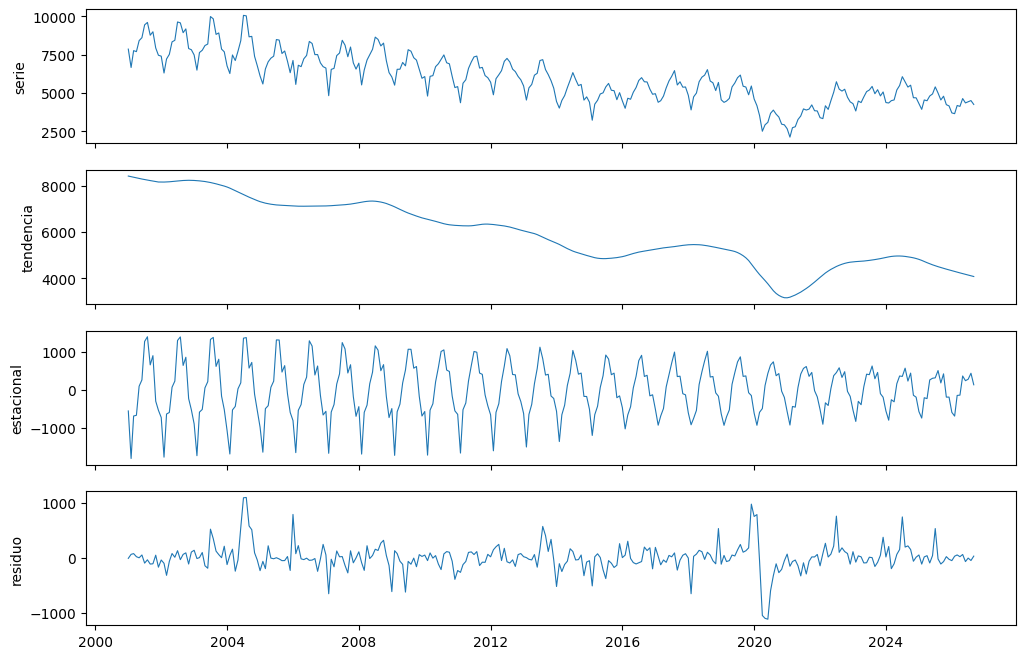

{'mes_alto': 'agosto', 'mes_bajo': 'febrero', 'amplitud_pct_media': 37.6}

In [5]:
from delitos_chicago.temporal import descomposicion_stl, resumen_estacionalidad
stl = descomposicion_stl(df, "THEFT", hasta=str(mes_completo.date()))
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, (nombre, datos) in zip(axes, stl.items()):
    ax.plot(datos, linewidth=0.8)
    ax.set_ylabel(nombre)
plt.show()
resumen_estacionalidad(stl)

## 4. COVID-19: serie temporal interrumpida

Modelo OLS del logaritmo de la media diaria mensual con tendencia lineal y 11 indicadores de mes, ajustado entre 2015-01 y 2020-02. El contrafactual se proyecta a 2020-03 – 2021-12 y los intervalos de predicción (95 %) se obtienen simulando coeficientes y ruido residual.

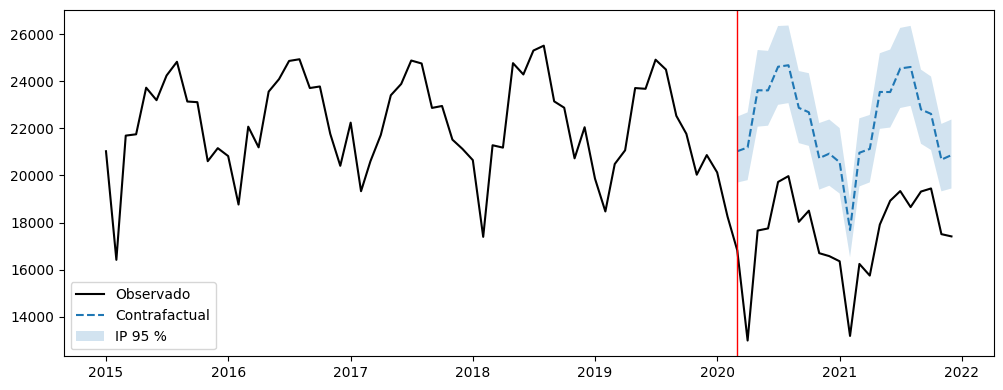

{'inicio_pre': '2015-01-01',
 'fin_pre': '2020-02-01',
 'intervencion': '2020-03-01',
 'fin_evaluacion': '2021-12-01',
 'meses_pre': 62,
 'nivel_intervalo': 0.95,
 'tendencia_pre_pct_anual': -0.3,
 'mape_ajuste_pre_pct': 1.9,
 'observado_total': 384717,
 'contrafactual_total': 489595,
 'diferencia_total': -104878,
 'diferencia_inf': -116985,
 'diferencia_sup': -93521,
 'cambio_pct': -21.4,
 'cambio_inf_pct': -23.3,
 'cambio_sup_pct': -19.6,
 'meses_fuera_intervalo': 22,
 'meses_evaluados': 22}

In [6]:
from delitos_chicago.temporal import efecto_covid_por_serie, serie_interrumpida, serie_mensual
mensual = serie_mensual(df)
mensual = mensual[mensual.index <= mes_completo]
its = serie_interrumpida(mensual)
t = its["tabla"]
ventana = mensual["2015":"2021"]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(ventana.index, ventana.values, color="black", label="Observado")
ax.plot(t["mes"], t["contrafactual"], "--", label="Contrafactual")
ax.fill_between(t["mes"], t["pi_inf"], t["pi_sup"], alpha=0.2, label="IP 95 %")
ax.axvline(pd.Timestamp("2020-03-01"), color="red", linewidth=1)
ax.legend()
plt.show()
its["resumen"]

In [7]:
series = {
    "Todos": mensual,
    "THEFT": serie_mensual(df, df["tipo_primario"] == "THEFT"),
    "BATTERY": serie_mensual(df, df["tipo_primario"] == "BATTERY"),
    "Violencia doméstica": serie_mensual(df, df["domestico"] == True),
}
efecto_covid_por_serie({k: v[v.index <= mes_completo] for k, v in series.items()})

,serie,choque_abr_may_2020_pct,cambio_pct,cambio_inf_pct,cambio_sup_pct,meses_fuera_intervalo,meses_evaluados,mape_ajuste_pre_pct
0,Todos,-31.6,-21.4,-23.3,-19.6,22,22,1.9
1,THEFT,-49.0,-41.1,-43.6,-38.7,22,22,3.7
2,BATTERY,-29.9,-19.2,-21.5,-17.0,22,22,2.4
3,Violencia doméstica,-23.8,-10.8,-13.1,-8.7,20,22,2.2


La caída es clara y fuera del intervalo de predicción en todos los meses evaluados. No es un efecto causal aislado: en 2020 coincidieron el confinamiento, las protestas y cambios en el patrullaje.

## 5. Cambio de composición 2019 → 2024 (categorías armonizadas)

In [8]:
from delitos_chicago.temporal import cambio_porcentual_por_tipo
cambio = cambio_porcentual_por_tipo(df, 2019, 2024)
cambio[cambio["conteo_2019"] >= 100]

,tipo_primario,conteo_2019,conteo_2024,cambio_pct
0,MOTOR VEHICLE THEFT,8979,21713,141.8
1,STALKING,228,520,128.1
3,ARSON,376,481,27.9
4,WEAPONS VIOLATION,6339,7841,23.7
5,HOMICIDE,509,597,17.3
6,ROBBERY,7997,9120,14.0
7,ASSAULT,20626,23488,13.9
8,CRIMINAL DAMAGE,26683,28557,7.0
10,OTHER OFFENSE,16813,17169,2.1
11,INTIMIDATION,163,164,0.6
